In [23]:
import pandas as pd

df= pd.read_excel("real_estate_transactions_enriched.xlsx")

X= df.drop(columns=["valor_instrumento","valor_pagto","cadastro",
                    "numero_imovel","matricula"])
y= df["valor_instrumento"]

for colname in X.select_dtypes(include=["object", "category", "str"]):
    X[colname], _ = X[colname].factorize()

discrete_features = X.dtypes == int


In [18]:
from sklearn.feature_selection import mutual_info_regression
import pandas as pd

X_mi = X.copy()

# Datas → número de dias desde 1970
for col in X_mi.select_dtypes(include=["datetime", "datetimetz"]):
    X_mi[col] = X_mi[col].astype("int64") // 10**9

# Textos/categorias → códigos inteiros
for col in X_mi.select_dtypes(include=["object", "category"]):
    X_mi[col], _ = pd.factorize(X_mi[col])

# Booleanos → 0/1
for col in X_mi.select_dtypes(include=["bool"]):
    X_mi[col] = X_mi[col].astype(int)

# MI não aceita valores ausentes
X_mi = X_mi.fillna(X_mi.median(numeric_only=True)).fillna(0)

# Colunas inteiras são tratadas como discretas
discrete_features = X_mi.dtypes.isin(["int64", "int32", "bool"])

mi_scores = make_mi_scores(X_mi, y, discrete_features)
mi_scores[mi_scores>0]

endereco_imovel                            1.083711
bairro                                     1.049701
data_emissao                               0.549579
taxa_pagto_sobre_instrumento_pct           0.545016
lote                                       0.502130
quadra                                     0.418504
natureza_transacao                         0.367401
mes_referencia                             0.348509
saldo_credito_habitacional_r_milhoes       0.346602
saldo_credito_habitacional_yoy_pct         0.343303
endividamento_familias_ex_habitacao_pct    0.340169
selic_mes_pct                              0.294281
complemento                                0.280384
inadimplencia_financiamento_imob_pct       0.275662
juros_financiamento_imob_aa_pct            0.267365
juros_financiamento_imob_mes_pct           0.264790
exercicio                                  0.200454
is_financiada                              0.109817
is_transacao_forcada                       0.036327
porcentagem 

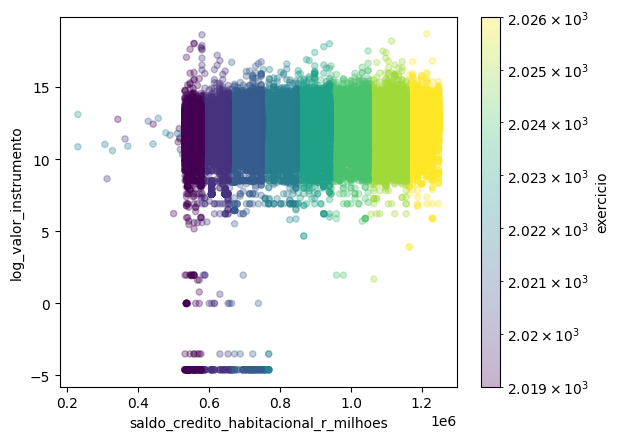

In [86]:
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm 
import numpy as np

df_= df[(df["longitude"].between(-47.4,-47)) & (df["latitude"].between(-23.2,-23))]
df_["log_saldo_credito_habitacional_r_milhoes"]= np.log(df["saldo_credito_habitacional_r_milhoes"])
df_["log_valor_instrumento"]= np.log(df["valor_instrumento"])

df_.plot.scatter(
    x="saldo_credito_habitacional_r_milhoes",
    y="log_valor_instrumento",
    c="exercicio",
    cmap="viridis",
    norm= LogNorm(),
    alpha=0.3,
    legend=False
)

plt.show()


In [ ]:
df.plot.scatter(x=, y="valor_instrumento", alpha=0.1)

c:\Users\Usuario\OneDrive\Área de Trabalho\tupan\ceres\.venv\Scripts\python.exe
